# [16.1] Exact Shapley on Ground-Truth Games (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part1_exact_shapley/16.1_Exact_Shapley_on_Ground-Truth_Games_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part1_exact_shapley/16.1_Exact_Shapley_on_Ground-Truth_Games_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="media/exact_shapley_ground_truth_signature.png" width="980">

# Introduction

**Core question:** when interactions make a player's contribution depend on context, does exact Shapley
recover the known dividend allocation while leave-one-out fails conservation?

**Claim:** on the four-player game in this notebook, exact Shapley matches an independent analytic oracle and
permutation averaging to numerical precision for every tested interaction strength; leave-one-out agrees only
in the additive control and overcounts by `4.5 * interaction_scale`.


## What you will implement

You will:

- enumerate and validate complete coalition tables;
- build a game from explicit Harsanyi dividends;
- implement exact Shapley as a weighted average of marginal contributions;
- derive an independent dividend-splitting oracle;
- test efficiency, symmetry, and the dummy-player property;
- reproduce the result by averaging over every player permutation;
- expose leave-one-out overcounting with an interaction-strength sweep.

Every scientific result below is generated from the visible finite game. No verification report is used as
lesson evidence.

## Content & Learning Objectives

### 1️⃣ Define the complete game

> ##### Learning Objectives
>
> - Enumerate and validate every coalition and construct its value from dividends.

### 2️⃣ Average over contexts

> ##### Learning Objectives
>
> - Implement weighted marginals and check efficiency, symmetry, a dummy player and permutation parity.

### 3️⃣ Conserve interaction credit

> ##### Learning Objectives
>
> - Explain leave-one-out overcounting and reproduce the full controlled signature plot.

### 4️⃣ Change the organism

> ##### Learning Objectives
>
> - Predict changed interaction strengths and test a sign-crossing explanation.

### ☆ Bonus

Derive an exact crossing and investigate negative interaction strengths.

## Setup code

The exact finite game and its local independent tests run on CPU. Keep the complete table and all declared
dividends fixed while reproducing the reference.

In [1]:
from collections.abc import Callable, Mapping
from dataclasses import dataclass
import itertools
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch as t

chapter = "chapter16_shapley_attribution_baselines"
section = "part1_exact_shapley"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
assets_dir = exercises_dir / section / "media"
for path in (root_dir, exercises_dir):
    if str(path) not in sys.path:
        sys.path.append(str(path))

import part1_exact_shapley.tests as tests

Coalition = frozenset[int]
t.set_grad_enabled(False)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})
EXACT = "#B43A32"
ORACLE = "#D39A2C"
BASELINE = "#167D8D"
CONTROL = "#5F6875"


@dataclass(frozen=True)
class ShapleyEfficiencyReport:
    shapley_sum: float
    total_value_delta: float
    efficiency_error: float
    satisfies_efficiency: bool


@dataclass(frozen=True)
class PermutationParityReport:
    max_abs_error: float
    matches_exact: bool


@dataclass(frozen=True)
class InteractionGapReport:
    shapley_total: float
    leave_one_out_total: float
    overcount: float
    detects_interaction_overcount: bool

## Cold open: one player, four answers

Player `1` has direct dividend `-0.2`. It also participates in a positive pair interaction, a negative pair
interaction, and a positive three-way interaction. Which number is its contribution?

- direct effect only: `-0.2`;
- leave-one-out from the full coalition: `1.9`;
- exact Shapley: `0.6`;
- a marginal contribution in one particular context: anything from `-0.8` to `1.9`.

The disagreement is the lesson. Shapley does not ask for one privileged context. It averages a player's
marginal contribution over every possible predecessor coalition with the weights induced by random player
orderings.

<details><summary>Interpretation - what can be exactly true here?</summary>

Because every coalition value and every dividend is declared, both the attribution target and the
counterexamples are exact. This organism tests Shapley mathematics. It is not evidence about the faithfulness
of masking tokens or ablating model components.

</details>

# 1️⃣ Define the complete game

> ##### Learning Objectives
>
> - Enumerate and validate every coalition and construct its value from dividends.

### Exercise - enumerate a complete game

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

A game with `n` players needs `2**n` coalition values, including the empty and full coalitions. Implement
enumeration, normalization, and table construction. Missing entries must fail loudly.

<details><summary>Help - common bug: incomplete coalition table</summary>

Loop over subset sizes and use `itertools.combinations`. Store coalitions as `frozenset` so they can be
dictionary keys. During normalization, compare the actual key set with the complete power set.

</details>

<details><summary>Solution</summary>

```python
def all_coalitions(num_players):
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    return tuple(
        frozenset(group)
        for size in range(num_players + 1)
        for group in itertools.combinations(range(num_players), size)
    )

def normalize_coalition_values(values, *, num_players):
    normalized = {frozenset(key): float(value) for key, value in values.items()}
    expected = set(all_coalitions(num_players))
    missing = expected - set(normalized)
    extra = set(normalized) - expected
    if missing or extra:
        raise ValueError(f"coalition table has missing coalitions={len(missing)} and extra coalitions={len(extra)}")
    return {coalition: normalized[coalition] for coalition in all_coalitions(num_players)}

def coalition_values_from_function(num_players, value_fn):
    return {coalition: float(value_fn(coalition)) for coalition in all_coalitions(num_players)}
```

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_all_coalitions_enumerates_the_power_set` passed!
All tests in `test_complete_table_normalization` passed!
```

</details>

<details><summary>Interpretation</summary>

Rejecting an incomplete table protects the definition of the game. Treating an unmeasured coalition as zero
silently changes both the baseline and interaction structure.

</details>

For four players, predict the number of required entries and whether removing the empty coalition should raise
an error. Explain why treating a missing entry as zero changes the game. Changed case: predict the entry count
for five players.

In [2]:
def all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    return tuple(
        frozenset(group)
        for size in range(num_players + 1)
        for group in itertools.combinations(range(num_players), size)
    )


def normalize_coalition_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> dict[Coalition, float]:
    normalized = {
        frozenset(key): float(value) for key, value in coalition_values.items()
    }
    expected = set(all_coalitions(num_players))
    missing = expected - set(normalized)
    extra = set(normalized) - expected
    if missing or extra:
        raise ValueError(
            "coalition table has "
            f"missing coalitions={len(missing)} and extra coalitions={len(extra)}"
        )
    return {
        coalition: normalized[coalition]
        for coalition in all_coalitions(num_players)
    }


def coalition_values_from_function(
    num_players: int,
    value_fn: Callable[[Coalition], float],
) -> dict[Coalition, float]:
    return {
        coalition: float(value_fn(coalition))
        for coalition in all_coalitions(num_players)
    }
tests.test_all_coalitions_enumerates_the_power_set(all_coalitions)
tests.test_complete_table_normalization(
    all_coalitions,
    normalize_coalition_values,
    coalition_values_from_function,
)

All tests in `test_all_coalitions_enumerates_the_power_set` passed!
All tests in `test_complete_table_normalization` passed!


Before the oracle is printed, predict whether increasing the baseline from 0.3 to 2.3 changes player credit or
full-minus-empty value. Use the declared direct, pair and triple dividends to predict player 1's allocation.

In [3]:
PLAYER_NAMES = ("input", "memory", "router", "readout")
DIRECT_DIVIDENDS = {
    frozenset({0}): 0.8,
    frozenset({1}): -0.2,
    frozenset({2}): 0.4,
    frozenset({3}): 0.1,
}
INTERACTION_DIVIDENDS = {
    frozenset({0, 1}): 1.2,
    frozenset({1, 2}): -0.6,
    frozenset({2, 3}): 0.9,
    frozenset({0, 1, 2}): 1.5,
}
BASELINE_VALUE = 0.3

def scaled_dividends(interaction_scale: float = 1.0) -> dict[Coalition, float]:
    return DIRECT_DIVIDENDS | {
        term: float(interaction_scale) * value
        for term, value in INTERACTION_DIVIDENDS.items()
    }
def game_from_dividends(
    num_players: int,
    dividends: Mapping[Coalition | tuple[int, ...], float],
    baseline: float = 0.0,
) -> dict[Coalition, float]:
    normalized = {
        frozenset(term): float(value) for term, value in dividends.items()
    }
    if any(not term for term in normalized):
        raise ValueError("Use baseline for the empty dividend.")
    if any(player < 0 or player >= num_players for term in normalized for player in term):
        raise ValueError("Dividend contains a player outside the game.")
    return coalition_values_from_function(
        num_players,
        lambda coalition: float(baseline)
        + sum(
            value for term, value in normalized.items()
            if term.issubset(coalition)
        ),
    )


def shapley_from_dividends(
    num_players: int,
    dividends: Mapping[Coalition | tuple[int, ...], float],
) -> t.Tensor:
    result = t.zeros(num_players, dtype=t.float64)
    for raw_term, raw_dividend in dividends.items():
        term = frozenset(raw_term)
        if not term:
            raise ValueError("The empty dividend is a baseline, not player credit.")
        for player in term:
            result[player] += float(raw_dividend) / len(term)
    return result
tests.test_dividend_game_and_analytic_oracle(
    game_from_dividends,
    shapley_from_dividends,
)
organism_dividends = scaled_dividends(1.0)
organism_values = game_from_dividends(
    4, organism_dividends, baseline=BASELINE_VALUE
)
analytic_oracle = shapley_from_dividends(4, organism_dividends)
full_coalition = frozenset(range(4))
print(
    f"Empty value = {organism_values[frozenset()]:.3f}; "
    f"full value = {organism_values[full_coalition]:.3f}; "
    f"total delta = {organism_values[full_coalition] - organism_values[frozenset()]:.3f}"
)
print("Analytic oracle =", [round(value, 3) for value in analytic_oracle.tolist()])
print("\nComplete coalition table:")
for coalition, value in organism_values.items():
    names = ", ".join(PLAYER_NAMES[player] for player in sorted(coalition)) or "empty"
    print(f"  {str(sorted(coalition)):<14} {names:<31} value={value:5.2f}")

All tests in `test_dividend_game_and_analytic_oracle` passed!
Empty value = 0.300; full value = 4.400; total delta = 4.100
Analytic oracle = [1.9, 0.6, 1.05, 0.55]

Complete coalition table:
  []             empty                           value= 0.30
  [0]            input                           value= 1.10
  [1]            memory                          value= 0.10
  [2]            router                          value= 0.70
  [3]            readout                         value= 0.40
  [0, 1]         input, memory                   value= 2.10
  [0, 2]         input, router                   value= 1.50
  [0, 3]         input, readout                  value= 1.20
  [1, 2]         memory, router                  value=-0.10
  [1, 3]         memory, readout                 value= 0.20
  [2, 3]         router, readout                 value= 1.70
  [0, 1, 2]      input, memory, router           value= 3.40
  [0, 1, 3]      input, memory, readout          value= 2.20
  [0, 2, 3]     

# 2️⃣ Average over contexts

> ##### Learning Objectives
>
> - Implement weighted marginals and check efficiency, symmetry, a dummy player and permutation parity.

### Exercise - implement weighted marginal Shapley

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

For player `i`, enumerate every coalition `S` that excludes `i`. Record the marginal `v(S union {i}) - v(S)`
and its permutation weight:

$$w(S)=
rac{{|S|!(n-|S|-1)!}}{{n!}}.$$

Implement the context table first, then compute exact Shapley as its weighted sum.

<details><summary>Help</summary>

There are `2**(n-1)` rows for each player. The weights across those rows sum to one. Do not average the rows
uniformly: coalition sizes occur with different multiplicities in permutations.

</details>

<details><summary>Solution</summary>

```python
def marginal_contribution_rows(values, *, num_players, player):
    values = normalize_coalition_values(values, num_players=num_players)
    rows = []
    for coalition in all_coalitions(num_players):
        if player in coalition:
            continue
        size = len(coalition)
        weight = math.factorial(size) * math.factorial(num_players-size-1) / math.factorial(num_players)
        marginal = values[coalition | {player}] - values[coalition]
        rows.append((coalition, marginal, weight))
    return tuple(rows)

def exact_shapley_values(values, *, num_players):
    return t.tensor([
        sum(marginal * weight for _, marginal, weight in marginal_contribution_rows(values, num_players=num_players, player=player))
        for player in range(num_players)
    ], dtype=t.float64)
```

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_weighted_marginal_rows` passed!
All tests in `test_additive_game_and_exact_shapley_recover_weights` passed!
All tests in `test_exact_shapley_requires_a_complete_coalition_table` passed!
Exact Shapley = [1.900, 0.600, 1.050, 0.550]
```

</details>

<details><summary>Interpretation</summary>

The marginal rows make context dependence visible. Shapley is the expectation over random predecessor
coalitions, not the marginal in the empty or full context alone.

</details>

For player 1, predict whether a uniform average over its eight predecessor sets equals the
permutation-weighted average. Explain how many orderings give a particular set of size zero, one, two or
three. Predict the sign of any discrepancy.

In [4]:
def marginal_contribution_rows(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    player: int,
) -> tuple[tuple[Coalition, float, float], ...]:
    if player < 0 or player >= num_players:
        raise ValueError("player must index this game.")
    values = normalize_coalition_values(
        coalition_values, num_players=num_players
    )
    rows = []
    denominator = math.factorial(num_players)
    for coalition in all_coalitions(num_players):
        if player in coalition:
            continue
        size = len(coalition)
        weight = (
            math.factorial(size)
            * math.factorial(num_players - size - 1)
            / denominator
        )
        marginal = values[coalition | {player}] - values[coalition]
        rows.append((coalition, marginal, weight))
    return tuple(rows)


def exact_shapley_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> t.Tensor:
    result = t.zeros(num_players, dtype=t.float64)
    for player in range(num_players):
        result[player] = sum(
            marginal * weight
            for _, marginal, weight in marginal_contribution_rows(
                coalition_values,
                num_players=num_players,
                player=player,
            )
        )
    return result


def additive_game(weights: t.Tensor) -> dict[Coalition, float]:
    weights = weights.detach().flatten().double()
    return coalition_values_from_function(
        int(weights.numel()),
        lambda coalition: weights[list(coalition)].sum().item()
        if coalition else 0.0,
    )
tests.test_weighted_marginal_rows(marginal_contribution_rows)
tests.test_additive_game_and_exact_shapley_recover_weights(
    additive_game,
    exact_shapley_values,
)
tests.test_exact_shapley_requires_a_complete_coalition_table(
    exact_shapley_values
)
exact_values = exact_shapley_values(organism_values, num_players=4)
print("Exact Shapley =", [round(value, 3) for value in exact_values.tolist()])

All tests in `test_weighted_marginal_rows` passed!
All tests in `test_additive_game_and_exact_shapley_recover_weights` passed!
All tests in `test_exact_shapley_requires_a_complete_coalition_table` passed!
Exact Shapley = [1.9, 0.6, 1.05, 0.55]


In [5]:
player_one_rows = marginal_contribution_rows(
    organism_values, num_players=4, player=1
)
print("Player 1 marginal contributions by predecessor context:")
print("  coalition        marginal   weight   weighted")
for coalition, marginal, weight in player_one_rows:
    print(
        f"  {str(sorted(coalition)):<16} {marginal:>7.2f}   "
        f"{weight:>6.3f}   {marginal * weight:>8.3f}"
    )
print("  weighted sum:", round(sum(m * w for _, m, w in player_one_rows), 3))

Player 1 marginal contributions by predecessor context:
  coalition        marginal   weight   weighted
  []                 -0.20    0.250     -0.050
  [0]                 1.00    0.083      0.083
  [2]                -0.80    0.083     -0.067
  [3]                -0.20    0.083     -0.017
  [0, 2]              1.90    0.083      0.158
  [0, 3]              1.00    0.083      0.083
  [2, 3]             -0.80    0.083     -0.067
  [0, 2, 3]           1.90    0.250      0.475
  weighted sum: 0.6


Predict the three-player conjunction allocation, the fifth dummy player's credit, and the four-player
efficiency error. State which separate failure each control can detect.

In [6]:
def conjunction_game(num_players: int) -> dict[Coalition, float]:
    full = frozenset(range(num_players))
    return coalition_values_from_function(
        num_players, lambda coalition: coalition == full
    )


def shapley_efficiency_report(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    tolerance: float = 1e-9,
) -> ShapleyEfficiencyReport:
    values = normalize_coalition_values(
        coalition_values, num_players=num_players
    )
    shapley_sum = exact_shapley_values(
        values, num_players=num_players
    ).sum().item()
    delta = (
        values[frozenset(range(num_players))]
        - values[frozenset()]
    )
    error = abs(shapley_sum - delta)
    return ShapleyEfficiencyReport(
        shapley_sum=shapley_sum,
        total_value_delta=delta,
        efficiency_error=error,
        satisfies_efficiency=error <= tolerance,
    )
tests.test_conjunction_game_splits_symmetric_credit_and_checks_efficiency(
    conjunction_game,
    exact_shapley_values,
    shapley_efficiency_report,
)
efficiency = shapley_efficiency_report(organism_values, num_players=4)
oracle_error = (exact_values - analytic_oracle).abs().max().item()
dummy_values = game_from_dividends(
    5, organism_dividends, baseline=BASELINE_VALUE
)
dummy_attribution = exact_shapley_values(dummy_values, num_players=5)[4].item()
assert oracle_error < 1e-12
assert abs(dummy_attribution) < 1e-12
print(f"Oracle max error: {oracle_error:.2e}")
print(f"Dummy player attribution: {dummy_attribution:.3f}")
print(f"Efficiency error: {efficiency.efficiency_error:.2e}")

All tests in `test_conjunction_game_splits_symmetric_credit_and_checks_efficiency` passed!
Oracle max error: 2.22e-16
Dummy player attribution: 0.000
Efficiency error: 0.00e+00


Predict how many orderings the four-player parity check visits and whether permuting player labels can change
the total allocated credit. Explain why a last-player marginal alone is insufficient.

In [7]:
def permutation_shapley_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> t.Tensor:
    values = normalize_coalition_values(
        coalition_values, num_players=num_players
    )
    result = t.zeros(num_players, dtype=t.float64)
    for ordering in itertools.permutations(range(num_players)):
        before = frozenset()
        for player in ordering:
            result[player] += (
                values[before | {player}] - values[before]
            )
            before = before | {player}
    return result / math.factorial(num_players)


def permutation_parity_report(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    tolerance: float = 1e-9,
) -> PermutationParityReport:
    exact = exact_shapley_values(
        coalition_values, num_players=num_players
    )
    permutation = permutation_shapley_values(
        coalition_values, num_players=num_players
    )
    error = float((exact - permutation).abs().max().item())
    return PermutationParityReport(
        max_abs_error=error,
        matches_exact=error <= tolerance,
    )
tests.test_permutation_parity_report_matches_exact_formula(
    conjunction_game,
    permutation_parity_report,
)
permutation_values = permutation_shapley_values(
    organism_values, num_players=4
)
permutation_error = (permutation_values - exact_values).abs().max().item()
print(
    f"Permutation max error: {permutation_error:.2e} "
    f"across {math.factorial(4)} orderings"
)

All tests in `test_permutation_parity_report_matches_exact_formula` passed!
Permutation max error: 1.11e-16 across 24 orderings


# 3️⃣ Conserve interaction credit

> ##### Learning Objectives
>
> - Explain leave-one-out overcounting and reproduce the full controlled signature plot.

### Exercise - expose the leave-one-out failure

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Leave-one-out uses only the full-coalition context: `v(N)-v(N minus {i})`. Implement it, then compare its
total credit with Shapley's conserved total.

<details><summary>Help</summary>

For each player, remove that player from the full coalition. The interaction gap is `sum(leave_one_out) -
sum(shapley)`. In a two-player AND game, this equals `1.0` because each player receives the full interaction
value.

</details>

<details><summary>Solution</summary>

```python
def leave_one_out_values(values, *, num_players):
    values = normalize_coalition_values(values, num_players=num_players)
    full = frozenset(range(num_players))
    return t.tensor([values[full] - values[full - {player}] for player in range(num_players)], dtype=t.float64)

def interaction_gap_report(values, *, num_players, min_overcount=0.5):
    shapley_total = exact_shapley_values(values, num_players=num_players).sum().item()
    loo_total = leave_one_out_values(values, num_players=num_players).sum().item()
    overcount = loo_total - shapley_total
    return InteractionGapReport(shapley_total, loo_total, overcount, overcount >= min_overcount)
```

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_interaction_gap_report_catches_leave_one_out_overcount` passed!
Leave-one-out = [3.500, 1.900, 2.200, 1.000]
Shapley total = 4.100; leave-one-out total = 8.600; overcount = 4.500
```

</details>

<details><summary>Interpretation</summary>

Leave-one-out is not merely noisy here. It answers a different question and counts each positive interaction
once for every participating player. Negative interactions can instead cause undercounting.

</details>

Predict Shapley's total, leave-one-out's total and their difference at scale 1. Count how often a pair
dividend and a triple dividend appear in the summed leave-one-out scores.

In [8]:
def leave_one_out_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> t.Tensor:
    values = normalize_coalition_values(
        coalition_values, num_players=num_players
    )
    full = frozenset(range(num_players))
    return t.tensor(
        [
            values[full] - values[full - {player}]
            for player in range(num_players)
        ],
        dtype=t.float64,
    )


def interaction_gap_report(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    min_overcount: float = 0.5,
) -> InteractionGapReport:
    shapley_total = exact_shapley_values(
        coalition_values, num_players=num_players
    ).sum().item()
    leave_one_out_total = leave_one_out_values(
        coalition_values, num_players=num_players
    ).sum().item()
    overcount = leave_one_out_total - shapley_total
    return InteractionGapReport(
        shapley_total=shapley_total,
        leave_one_out_total=leave_one_out_total,
        overcount=overcount,
        detects_interaction_overcount=overcount >= min_overcount,
    )
tests.test_interaction_gap_report_catches_leave_one_out_overcount(
    conjunction_game,
    interaction_gap_report,
)
leave_one_out = leave_one_out_values(organism_values, num_players=4)
interaction_gap = interaction_gap_report(organism_values, num_players=4)
print("Leave-one-out =", [round(value, 3) for value in leave_one_out.tolist()])
print(
    f"Shapley total = {interaction_gap.shapley_total:.3f}; "
    f"leave-one-out total = {interaction_gap.leave_one_out_total:.3f}; "
    f"overcount = {interaction_gap.overcount:.3f}"
)

All tests in `test_interaction_gap_report_catches_leave_one_out_overcount` passed!
Leave-one-out = [3.5, 1.9, 2.2, 1.0]
Shapley total = 4.100; leave-one-out total = 8.600; overcount = 4.500


Predict the leave-one-out surplus at scales 0, 0.5, 1 and 2, alongside the efficiency and dividend-oracle
errors. Derive the slope by counting each term's extra allocations. Changed case: predict the surplus at scale
-0.5.

In [9]:
def interaction_scale_sweep(scales: t.Tensor) -> dict[str, t.Tensor]:
    scales = scales.detach().flatten().double()
    efficiency_errors = []
    oracle_errors = []
    overcounts = []
    for scale in scales.tolist():
        dividends = scaled_dividends(scale)
        values = game_from_dividends(
            4, dividends, baseline=BASELINE_VALUE
        )
        exact = exact_shapley_values(values, num_players=4)
        oracle = shapley_from_dividends(4, dividends)
        efficiency_errors.append(
            shapley_efficiency_report(
                values, num_players=4
            ).efficiency_error
        )
        oracle_errors.append((exact - oracle).abs().max().item())
        overcounts.append(
            leave_one_out_values(values, num_players=4).sum().item()
            - exact.sum().item()
        )
    return {
        "shapley_efficiency_error": t.tensor(
            efficiency_errors, dtype=t.float64
        ),
        "oracle_max_error": t.tensor(
            oracle_errors, dtype=t.float64
        ),
        "leave_one_out_overcount": t.tensor(
            overcounts, dtype=t.float64
        ),
    }
tests.test_interaction_scale_sweep(interaction_scale_sweep)
sweep_scales = t.linspace(0.0, 2.0, 9, dtype=t.float64)
sweep = interaction_scale_sweep(sweep_scales)
print(f"Additive control overcount = {sweep['leave_one_out_overcount'][0]:.3f}")
print(f"Scale-1 overcount = {sweep['leave_one_out_overcount'][4]:.3f}")
print(f"Scale-2 overcount = {sweep['leave_one_out_overcount'][-1]:.3f}")

All tests in `test_interaction_scale_sweep` passed!
Additive control overcount = 0.000
Scale-1 overcount = 4.500
Scale-2 overcount = 9.000


## Signature Result

Generate all three panels from your implementations. The analytic dividend oracle and permutation result are
independent parity controls. The additive game at interaction scale `0` is the negative control for
leave-one-out failure.

Before inspecting the saved reference, forecast which bars coincide, which curve stays at numerical zero, and
which marginal contexts vary. Explain how the additive controls distinguish an interaction effect from a
baseline shift.

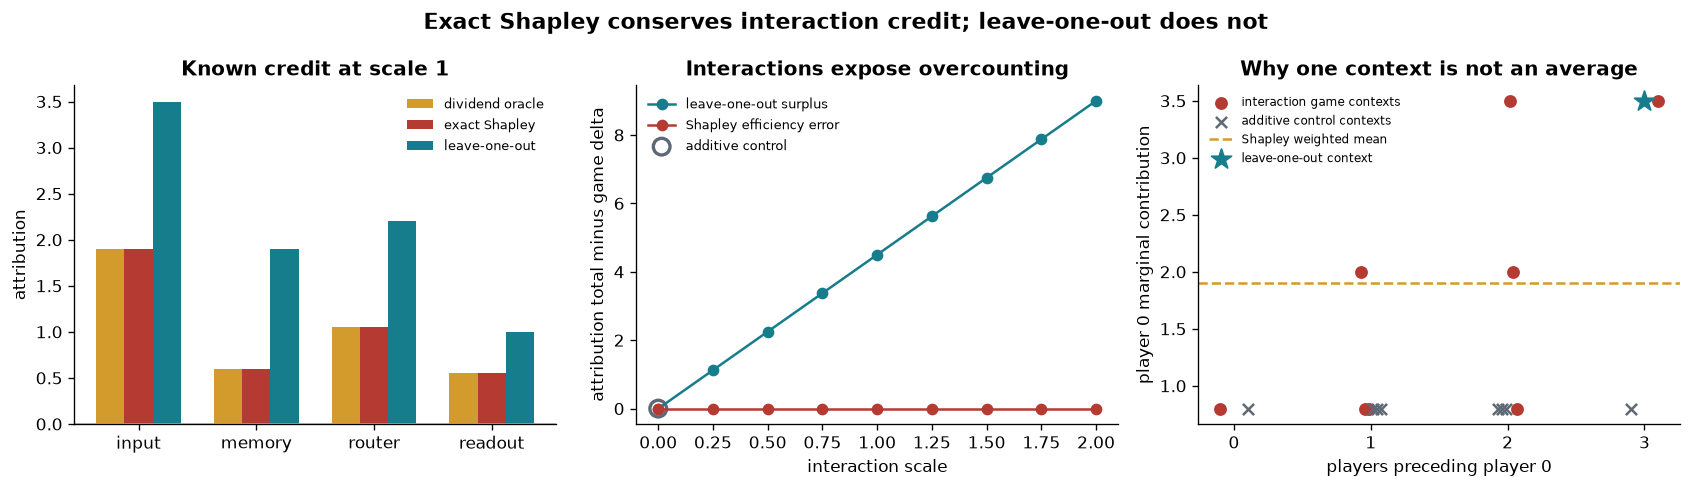

Signature metrics: oracle_error=2.22e-16, permutation_error=1.11e-16, efficiency_error=0.00e+00, leave_one_out_overcount=4.500, player0_marginal_range=[0.800, 3.500]


In [10]:
player_zero_rows = marginal_contribution_rows(
    organism_values, num_players=4, player=0
)
additive_values = game_from_dividends(
    4, DIRECT_DIVIDENDS, baseline=BASELINE_VALUE
)
additive_player_zero_rows = marginal_contribution_rows(
    additive_values, num_players=4, player=0
)

assert oracle_error < 1e-12
assert permutation_error < 1e-12
assert efficiency.efficiency_error < 1e-12
assert abs(interaction_gap.overcount - 4.5) < 1e-12
assert abs(sweep["leave_one_out_overcount"][-1].item() - 9.0) < 1e-12

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.1))
x = np.arange(len(PLAYER_NAMES))
width = 0.24
axes[0].bar(x - width, analytic_oracle, width, color=ORACLE, label="dividend oracle")
axes[0].bar(x, exact_values, width, color=EXACT, label="exact Shapley")
axes[0].bar(x + width, leave_one_out, width, color=BASELINE, label="leave-one-out")
axes[0].axhline(0, color="#B8BDC5", linewidth=1)
axes[0].set_xticks(x, PLAYER_NAMES)
axes[0].set_ylabel("attribution")
axes[0].set_title("Known credit at scale 1")
axes[0].legend(frameon=False, fontsize=8)

axes[1].plot(
    sweep_scales,
    sweep["leave_one_out_overcount"],
    marker="o",
    color=BASELINE,
    label="leave-one-out surplus",
)
axes[1].plot(
    sweep_scales,
    sweep["shapley_efficiency_error"],
    marker="o",
    color=EXACT,
    label="Shapley efficiency error",
)
axes[1].scatter([0], [0], s=100, facecolors="none", edgecolors=CONTROL, linewidths=2, label="additive control")
axes[1].set_xlabel("interaction scale")
axes[1].set_ylabel("attribution total minus game delta")
axes[1].set_title("Interactions expose overcounting")
axes[1].legend(frameon=False, fontsize=8)

context_sizes = [len(coalition) for coalition, _, _ in player_zero_rows]
marginals = [marginal for _, marginal, _ in player_zero_rows]
additive_marginals = [marginal for _, marginal, _ in additive_player_zero_rows]
offsets = np.linspace(-0.10, 0.10, len(context_sizes))
axes[2].scatter(
    np.array(context_sizes) + offsets,
    marginals,
    color=EXACT,
    s=45,
    label="interaction game contexts",
)
axes[2].scatter(
    np.array(context_sizes) - offsets,
    additive_marginals,
    color=CONTROL,
    marker="x",
    s=45,
    label="additive control contexts",
)
axes[2].axhline(exact_values[0].item(), color=ORACLE, linestyle="--", label="Shapley weighted mean")
axes[2].scatter([3], [leave_one_out[0].item()], color=BASELINE, marker="*", s=160, label="leave-one-out context")
axes[2].set_xticks([0, 1, 2, 3])
axes[2].set_xlabel("players preceding player 0")
axes[2].set_ylabel("player 0 marginal contribution")
axes[2].set_title("Why one context is not an average")
axes[2].legend(frameon=False, fontsize=7)

fig.suptitle(
    "Exact Shapley conserves interaction credit; leave-one-out does not",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout()
signature_path = assets_dir / "exact_shapley_ground_truth_signature.png"
fig.savefig(signature_path, dpi=170, bbox_inches="tight")
plt.show()

print(
    f"Signature metrics: oracle_error={oracle_error:.2e}, "
    f"permutation_error={permutation_error:.2e}, "
    f"efficiency_error={efficiency.efficiency_error:.2e}, "
    f"leave_one_out_overcount={interaction_gap.overcount:.3f}, "
    f"player0_marginal_range=[{min(marginals):.3f}, {max(marginals):.3f}]"
)

<details><summary>Interpreting the signature result</summary>

The oracle and exact bars coincide, including negative credit. Leave-one-out uses the largest-context marginal
and therefore inflates every positive interaction. The middle panel shows the falsifiable law for this
organism: Shapley efficiency error remains numerical zero while leave-one-out surplus grows from `0` to `9`.
The context panel explains the mechanism: player `0` contributes between `0.8` and `3.5` depending on which
players arrived first, and Shapley's weighted average is `1.9`.

</details>

In the reference scale-1 plot, all four Shapley bars are positive. The phrase "including negative
credit" above describes the signed-credit setting, not a negative bar in this particular panel. Use the
negative-scale play to check an actual negative allocation.

# 4️⃣ Change the organism

> ##### Learning Objectives
>
> - Predict changed interaction strengths and test a sign-crossing explanation.

### Try It Yourself - change the organism

Change `PLAY_INTERACTION_SCALE` and `PLAY_PLAYER`. Negative scales turn positive synergy into redundancy and
can make leave-one-out undercount. Keep the analytic oracle and efficiency checks active when you modify
dividends.

Choose PLAY_INTERACTION_SCALE and PLAY_PLAYER before running the play cell. Predict that player's Shapley
credit, full-context marginal and marginal range. Include a negative scale or bracket player 1's sign
crossing. Keep the dividend oracle check active.

In [11]:
PLAY_INTERACTION_SCALE = 0.5
PLAY_PLAYER = 1

play_dividends = scaled_dividends(PLAY_INTERACTION_SCALE)
play_values = game_from_dividends(4, play_dividends, baseline=BASELINE_VALUE)
play_shapley = exact_shapley_values(play_values, num_players=4)
play_oracle = shapley_from_dividends(4, play_dividends)
play_loo = leave_one_out_values(play_values, num_players=4)
play_rows = marginal_contribution_rows(
    play_values, num_players=4, player=PLAY_PLAYER
)
t.testing.assert_close(play_shapley, play_oracle, atol=1e-12, rtol=0)
print(f"Interaction scale: {PLAY_INTERACTION_SCALE:.2f}")
print(f"Player: {PLAY_PLAYER} ({PLAYER_NAMES[PLAY_PLAYER]})")
print(f"Shapley: {play_shapley[PLAY_PLAYER]:.3f}")
print(f"Leave-one-out: {play_loo[PLAY_PLAYER]:.3f}")
print(
    "Context marginals:",
    [round(marginal, 3) for _, marginal, _ in play_rows],
)

Interaction scale: 0.50
Player: 1 (memory)
Shapley: 0.200
Leave-one-out: 0.850
Context marginals: [-0.2, 0.4, -0.5, -0.2, 0.85, 0.4, -0.5, 0.85]


# ☆ Bonus

## Bonus anomaly hunt

Player `1` starts with a negative direct dividend but receives positive Shapley credit once interactions are
strong enough. Find the exact interaction scale where its attribution changes sign, then verify the crossing
numerically without changing any other dividend. Next, set the scale negative and explain why the
leave-one-out "overcount" becomes an undercount.

A strong anomaly report includes the derived crossing, the two neighboring numerical values, and the marginal
contexts responsible for the sign change.

## Limitations

- This is an exact four-player cooperative game, not an attribution result for a trained neural network.
- The dividend decomposition is supplied as ground truth. Real model components rarely arrive with known
interaction terms.
- Complete exact Shapley requires all `2**n` coalition values and all permutation parity checks require `n!`
orderings.
- The result says nothing about whether a masking or ablation operator creates in-distribution model inputs.
- Leave-one-out can overcount or undercount depending on interaction signs; this notebook's linear law is
specific to its declared dividends.

## Reading links

- [A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874)
- [Interpretable Machine Learning: Shapley
Values](https://christophm.github.io/interpretable-ml-book/shapley.html)
- [The Shapley Value and Harsanyi Dividends](https://doi.org/10.1016/0022-0531(88)90049-6)
- [Original ARENA toy-model
exercises](../../../chapter1_transformer_interp/exercises/part54_toy_models_of_superposition_and_saes/1.5.4_Toy_Models_of_Superposition_&_SAEs_exercises.ipynb)

In [12]:
def run_gpu_test(max_vram_gb: float = 24.0):
    from part1_exact_shapley_ground_truth_games.solutions import run_gpu_test as _run_gpu_test
    return _run_gpu_test(max_vram_gb=max_vram_gb)


def run_full_experiment(max_vram_gb: float = 24.0):
    return run_gpu_test(max_vram_gb=max_vram_gb)